<a href="https://colab.research.google.com/github/KGzB/CAS-Applied-Data-Science/blob/master/Module-2/CAS-D3-Hypothesis-Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Module 2, Project about statistics, CAS Applied Data Science, 2026-09-27, Simon Schüpbach.

# Statistics of PostAuto passenger numbers: Analysis of different line types


## Table of Contents

1. Introduction

    1.1 Data basis

    1.2 Motivation and Questions to be answered

2. Description and Aggregation of the Data

    2.1 Loading Libraries

    2.2 Loading and Visualisation of the Data Set

    2.2.1 High resolution data (passengers boarding by stop)

    2.2.2 Reducing the data set to four selected Bus Lines

3. Statistical Analysis of the four Bus Lines

    3.1 Touristic Lines

    3.2 Commuter Lines

4. Conclusion

## 1. Introduction

### 1.1 Data basis

There's data of boarding passengers of any line at any stop of the Swiss PostAuto in the time period of January 2024 to September 2026. This data set is not public and must therefore not be shared.

In a first step, the data is plotted and described as it is. Since the high resolution is not needed for further modelling or prediction at line and daytime resolution, the data is aggregated to suit the needs. 

### 1.2 Motivation and Questions to be answered

The data is thus aggregated by line, weekday type such as Mon-Fri and Sat-Sun, respectively, and time of day such as morning-noon and afternoon-evening. This aggregated data set is then analysed statistically in order to see if there are types of lines (e.g. commuter lines vs lines in touristic regions) that show simiar distributions. This can be useful for the clustering of lines with sufficiently similar distributions.

## 2. Description and Aggregation of the Data

### 2.1 Loading Libraries

First load all the libraries used in that notebook.


In [1]:
# load necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm
from scipy import stats

### 2.2 Loading and Visualisation of the Data Set

The data analysed in that notebook has been extracted from the internal data bases of PostAuto (see [CDR of that project](https://docs.google.com/document/d/1m9crP9a80fp3IzqoXkiingifm8n9IZrmlDQqiRC8w-8/edit?usp=sharing)). It is stored in AWS S3 buckets and was extracted from there using SQL queries. The data is then stored and exported as *.csv files which can be loaded here.

#### 2.2.1 High resulution data (passengers boarding by stop)

The data in stop resolution from all lines and covering the time period from beginning of 2026 to September 2026. For each line (there are approx. 1000 different lines in Switherland) and each tripnumber within those lines, the mean of boarding passengers is calculated by weekday.

In [7]:
line_data_path = 'c:\\Users/schue/Documents/Sonstiges/CAS_Data_Science/data/afz_trip_and_day_resolution_syslines_2601_651_700_709_202401-202609.csv'
stop_data_path = 'c:\\Users/schue/Documents/Sonstiges/CAS_Data_Science/data/afz_stop_resolution_202601-202608.csv'
line_profile_path = 'c:\\Users/schue/Documents/Sonstiges/CAS_Data_Science/data/afz_line_profiles_202602-202608.csv'

line_data_by_trip = pd.read_csv(line_data_path,sep=',')
line_profile_data = pd.read_csv(line_profile_path,sep=',')
stop_data_by_trip = pd.read_csv(stop_data_path,sep=';')
stop_data_by_trip = stop_data_by_trip.rename(
    columns={"_mean_boarding": "mean_boarding"}
)
# stop_data_by_trip['mean_boarding'].isna().sum()
stop_data_by_trip.head(5)
#line_profile_data.head(5)


,systemlinenumber,tripnumber,weekday,currentsequenceno,mean_boarding
0,1000,622001,Di,1,1.500000
1,1000,622001,Di,2,0.285714
2,1000,622001,Di,3,0.285714
3,1000,622001,Di,4,0.000000
4,1000,622001,Di,5,0.000000


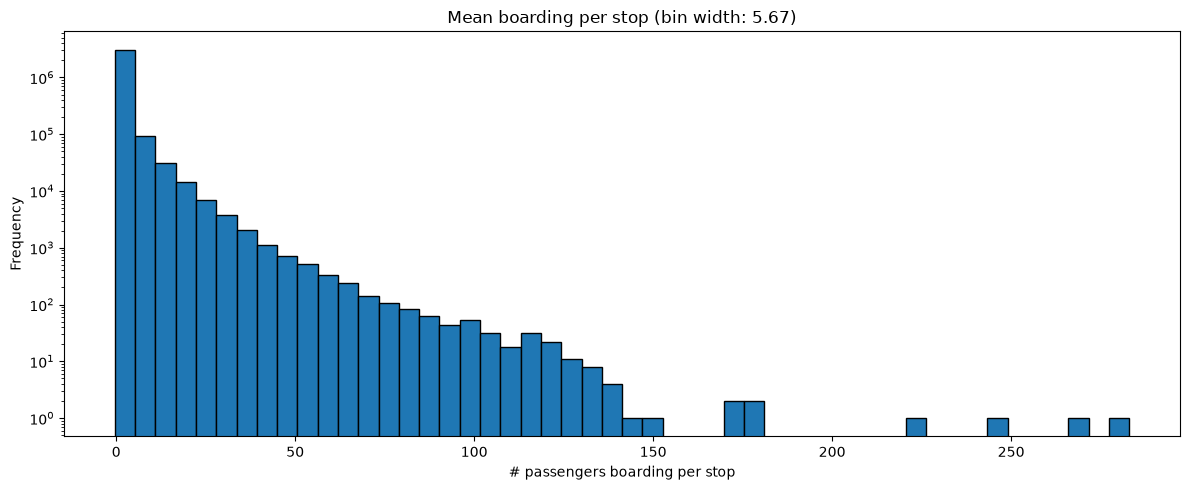

In [42]:

fig, ax = plt.subplots(figsize=(12, 5))

counts, bin_edges, bars = ax.hist(
    stop_data_by_trip["mean_boarding"],
    bins=50,
    edgecolor="black",
)

bin_width = bin_edges[1] - bin_edges[0]
# ax.bar_label(
#     bars,
#     labels=[f"{count:.0f}" for count in counts],
#     padding=2,
#     fontsize=7,
#     rotation=90,
# )
# ax.set_ylim(top=max(counts) * 1.2)
ax.set_yscale("log")
ax.set_xlabel("# passengers boarding per stop")
ax.set_ylabel("Frequency")
ax.set_title(f"Mean boarding per stop (bin width: {bin_width:.2f})")

plt.tight_layout()
plt.show()

In [43]:
first_bin_count = counts[0]
total_count = counts.sum()
first_bin_percentage = first_bin_count / total_count * 100

print(
    f"First bin: "
    f"{first_bin_count:,.0f} counts, {first_bin_percentage:.2f}% of all counts"
)

First bin: 3,076,170 counts, 95.16% of all counts


As can be seen, there are more than 3 millions of stops in the first bin, i.e. showing less than 5.67 boarding passengers. This corresponds to roughly 95% of all stops.

Therefore the data is further aggregated by systemlinenumber, weekday and time of the day (morning-noon vs afternoon-evening).

In [3]:
line_profile_data["time_of_day"] = np.where(
    line_profile_data["departurecet_h"] <= 13, "morning", "evening"
)
line_profile_data.head(5)

line_frequencies_halfdays = (
    line_profile_data
    .groupby([
        "weekday", "systemlinenumber", "time_of_day",
    ])
    .agg(mean_boarding_per_halfday=("mean_boarding_per_hour", "sum"))
    .reset_index()
)
line_frequencies_halfdays.head(5)

,weekday,systemlinenumber,time_of_day,mean_boarding_per_halfday
0,Di,11,evening,397
1,Di,11,morning,366
2,Di,20,evening,723
3,Di,20,morning,768
4,Di,30,evening,502


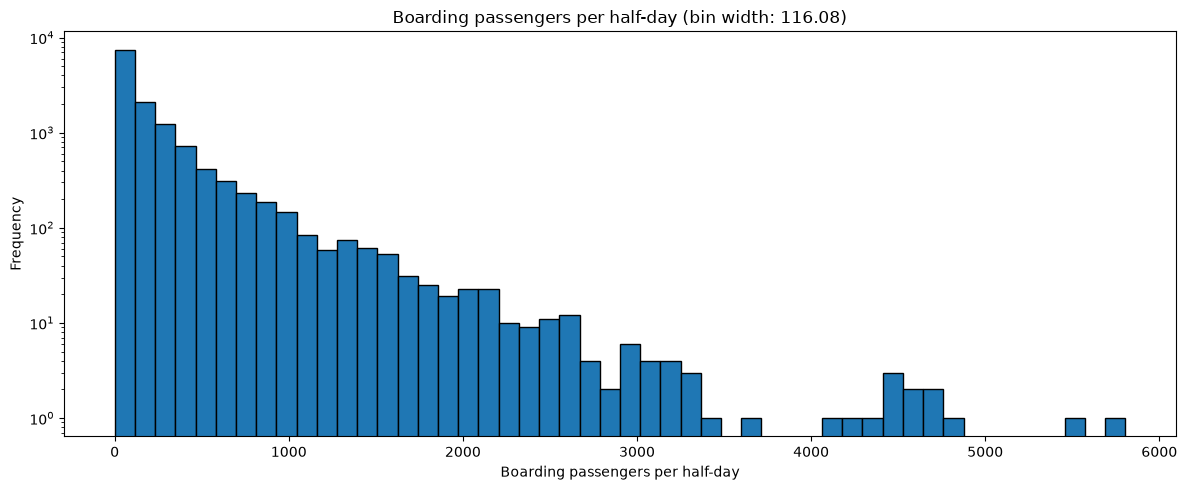

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

counts, bin_edges, bars = ax.hist(
    line_frequencies_halfdays["mean_boarding_per_halfday"],
    bins=50,
    edgecolor="black",
)

bin_width = bin_edges[1] - bin_edges[0]

ax.set_yscale("log")
ax.set_xlabel("Boarding passengers per half-day")
ax.set_ylabel("Frequency")
ax.set_title(f"Boarding passengers per half-day (bin width: {bin_width:.2f})")

plt.tight_layout()
plt.show()

Analysing all lines showing very heterogeniuos passenger numbers is not giving any deeper insights. Therefore, two typical commuter lines and two touristic lines are selected for further analysis.

#### 2.2.2 Analysing four selected bus lines

The data covering the entire time period (1.1.2024-30.9.2026) has already been aggregated in the SQL queries in order to provide reasonably sized data files.

In [9]:
line_data_by_trip["departure"] = (
    pd.to_datetime(line_data_by_trip["departure"], utc=True)
    .dt.tz_convert("Europe/Zurich")
)

line_data_by_trip["departure_h"] = line_data_by_trip["departure"].dt.hour
line_data_by_trip["time_of_day"] = np.where(
    line_data_by_trip["departure_h"] <= 13, "morning", "evening"
)
line_data_by_trip = line_data_by_trip.sort_values(
    ["operatingday", "systemlinenumber", "departure"]
).reset_index(drop=True)
line_data_by_trip.rename(
    columns={"systemlinenumber": "linenumber"},
    inplace=True,
)
line_data_by_trip["departure"] = line_data_by_trip["departure"].dt.strftime("%H:%M")
line_data_by_trip[(line_data_by_trip["operatingday"] == "2024-08-12") & (line_data_by_trip["time_of_day"] == "morning")].drop(["tripinstanceid","year_month", "month", "quart","departure_h"], axis=1).head(5)

C:\Users\schue\AppData\Local\Temp\ipykernel_12952\3450240996.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(line_data_by_trip["departure"], utc=True)


,operatingday,weekday,vehicleid,linenumber,tripnumber,directionid,departure,boarding_by_trip,weekdaytype,year,time_of_day
67754,2024-08-12,Mo,10453,651,551101,1,06:20,6.0,Mo-Fr,2024,morning
67755,2024-08-12,Mo,10083,651,551197,1,07:15,21.0,Mo-Fr,2024,morning
67756,2024-08-12,Mo,10453,651,551102,2,07:30,31.0,Mo-Fr,2024,morning
67757,2024-08-12,Mo,10082,651,551103,1,07:45,19.0,Mo-Fr,2024,morning
67758,2024-08-12,Mo,10087,651,551104,2,08:00,58.0,Mo-Fr,2024,morning


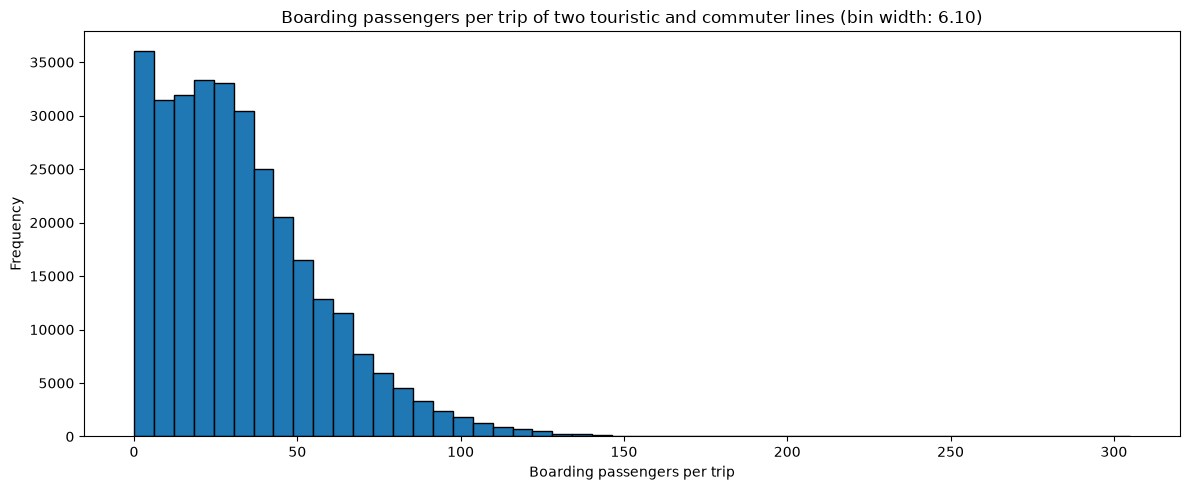

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

counts, bin_edges, bars = ax.hist(
    line_data_by_trip["boarding_by_trip"],
    bins=50,
    edgecolor="black",
)

bin_width = bin_edges[1] - bin_edges[0]

ax.set_yscale("linear")
ax.set_xlabel("Boarding passengers per trip")
ax.set_ylabel("Frequency")
ax.set_title(f"Boarding passengers per trip of two touristic and commuter lines (bin width: {bin_width:.2f})")

plt.tight_layout()
plt.show()

Since the number of trips with a very low passenger count (or even zero) is very high in that data set, it is further aggregated. I.e. We don't look at the trip level, but at the directions of the lines and at the daytime (morning/noon vs afternoon/evening).

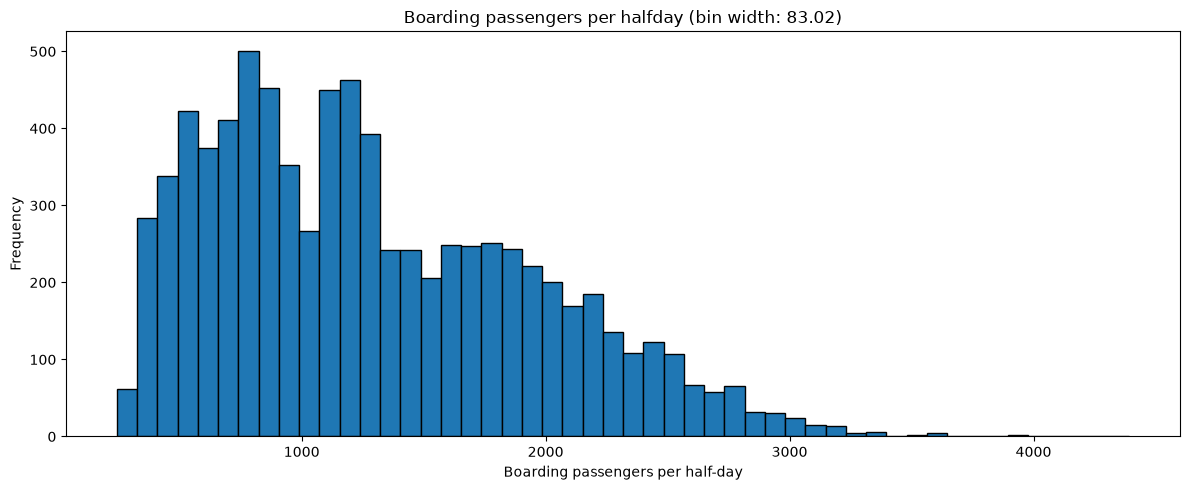

In [22]:
mean_passenger_frequencies_by_weekdaytype_timeofday = (
    line_data_by_trip
    .groupby([
        "year", "quart", "month", "operatingday", "weekday", "weekdaytype",
        "systemlinenumber", "time_of_day",
    ])
    .agg(boarding_mean=("boarding_by_trip", "sum"))
    .reset_index()
)
# mean_passenger_frequencies_by_weekdaytype_timeofday.head(5)
fig, ax = plt.subplots(figsize=(12, 5))

counts, bin_edges, bars = ax.hist(
    mean_passenger_frequencies_by_weekdaytype_timeofday["boarding_mean"],
    bins=50,
    edgecolor="black",
)

bin_width = bin_edges[1] - bin_edges[0]

ax.set_yscale("linear")
ax.set_xlabel("Boarding passengers per half-day")
ax.set_ylabel("Frequency")
ax.set_title(f"Boarding passengers per halfday (bin width: {bin_width:.2f})")

plt.tight_layout()
plt.show()

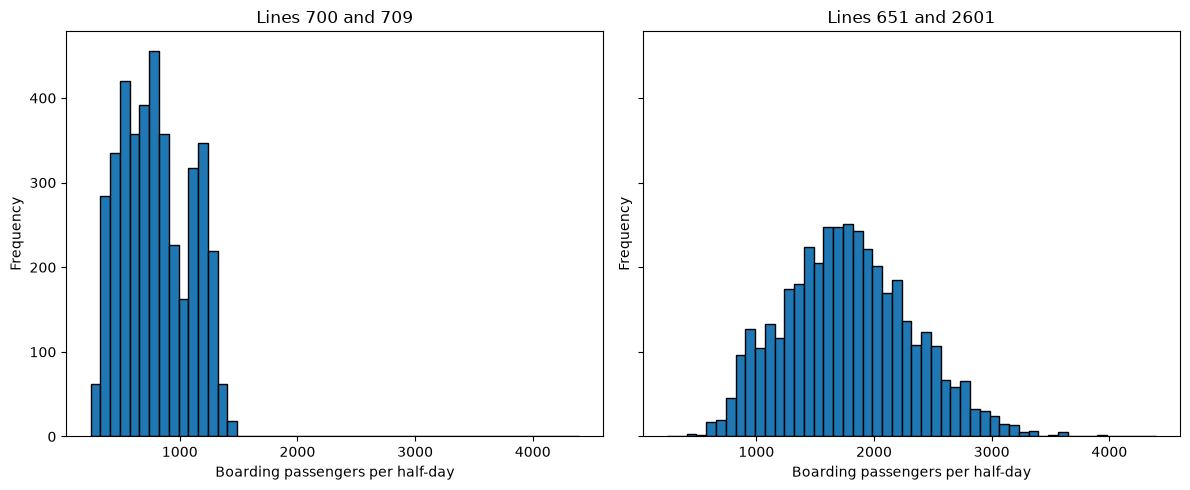

In [23]:
groups = {
    "Lines 700 and 709": [700, 709],
    "Lines 651 and 2601": [651, 2601],
}

all_values = mean_passenger_frequencies_by_weekdaytype_timeofday.loc[
    mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"].isin([700, 709, 651, 2601]),
    "boarding_mean",
].dropna()
bins = np.histogram_bin_edges(all_values, bins=50)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (title, line_numbers) in zip(axes, groups.items()):
    values = mean_passenger_frequencies_by_weekdaytype_timeofday.loc[
        mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"].isin(line_numbers),
        "boarding_mean",
    ].dropna()

    ax.hist(values, bins=bins, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Boarding passengers per half-day")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

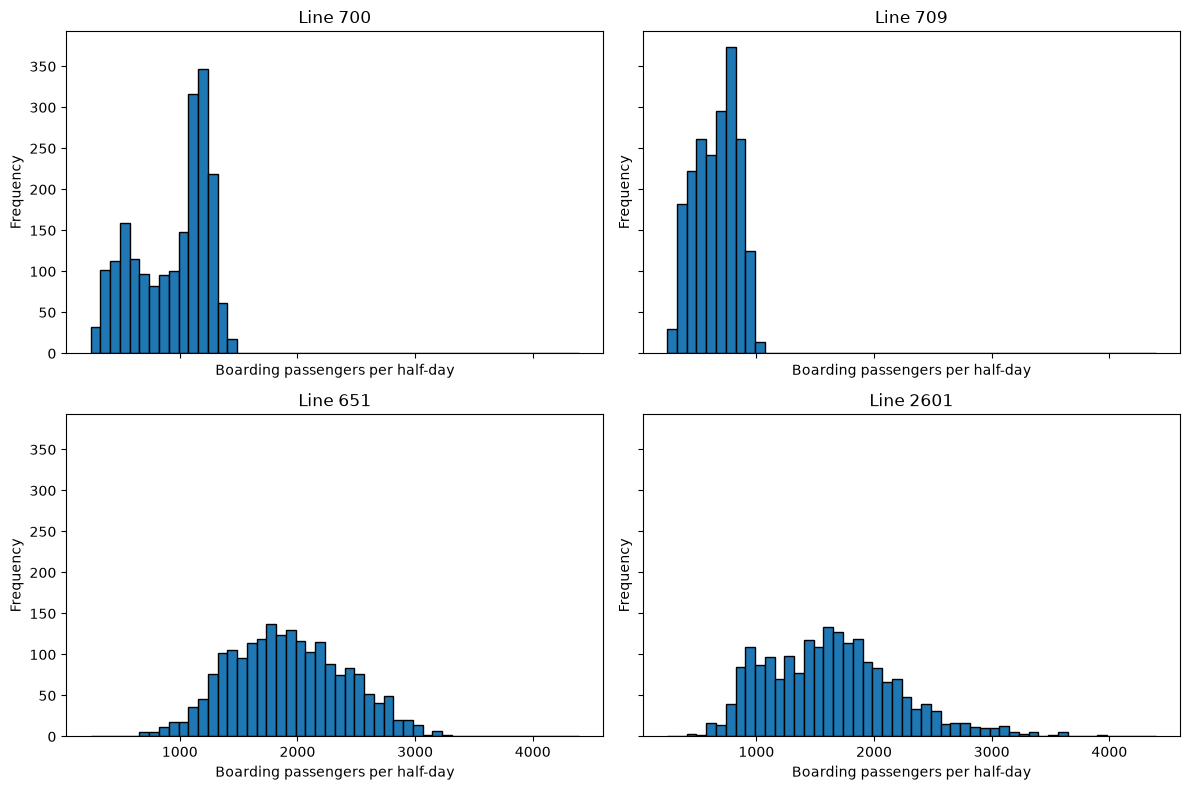

In [24]:
line_numbers = [700, 709, 651, 2601]

all_values = mean_passenger_frequencies_by_weekdaytype_timeofday.loc[
    mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"].isin(line_numbers),
    "boarding_mean",
].dropna()
bins = np.histogram_bin_edges(all_values, bins=50)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

for ax, line_number in zip(axes.flat, line_numbers):
    values = mean_passenger_frequencies_by_weekdaytype_timeofday.loc[
        mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"] == line_number,
        "boarding_mean",
    ].dropna()

    ax.hist(values, bins=bins, edgecolor="black")
    ax.set_title(f"Line {line_number}")
    ax.set_xlabel("Boarding passengers per half-day")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

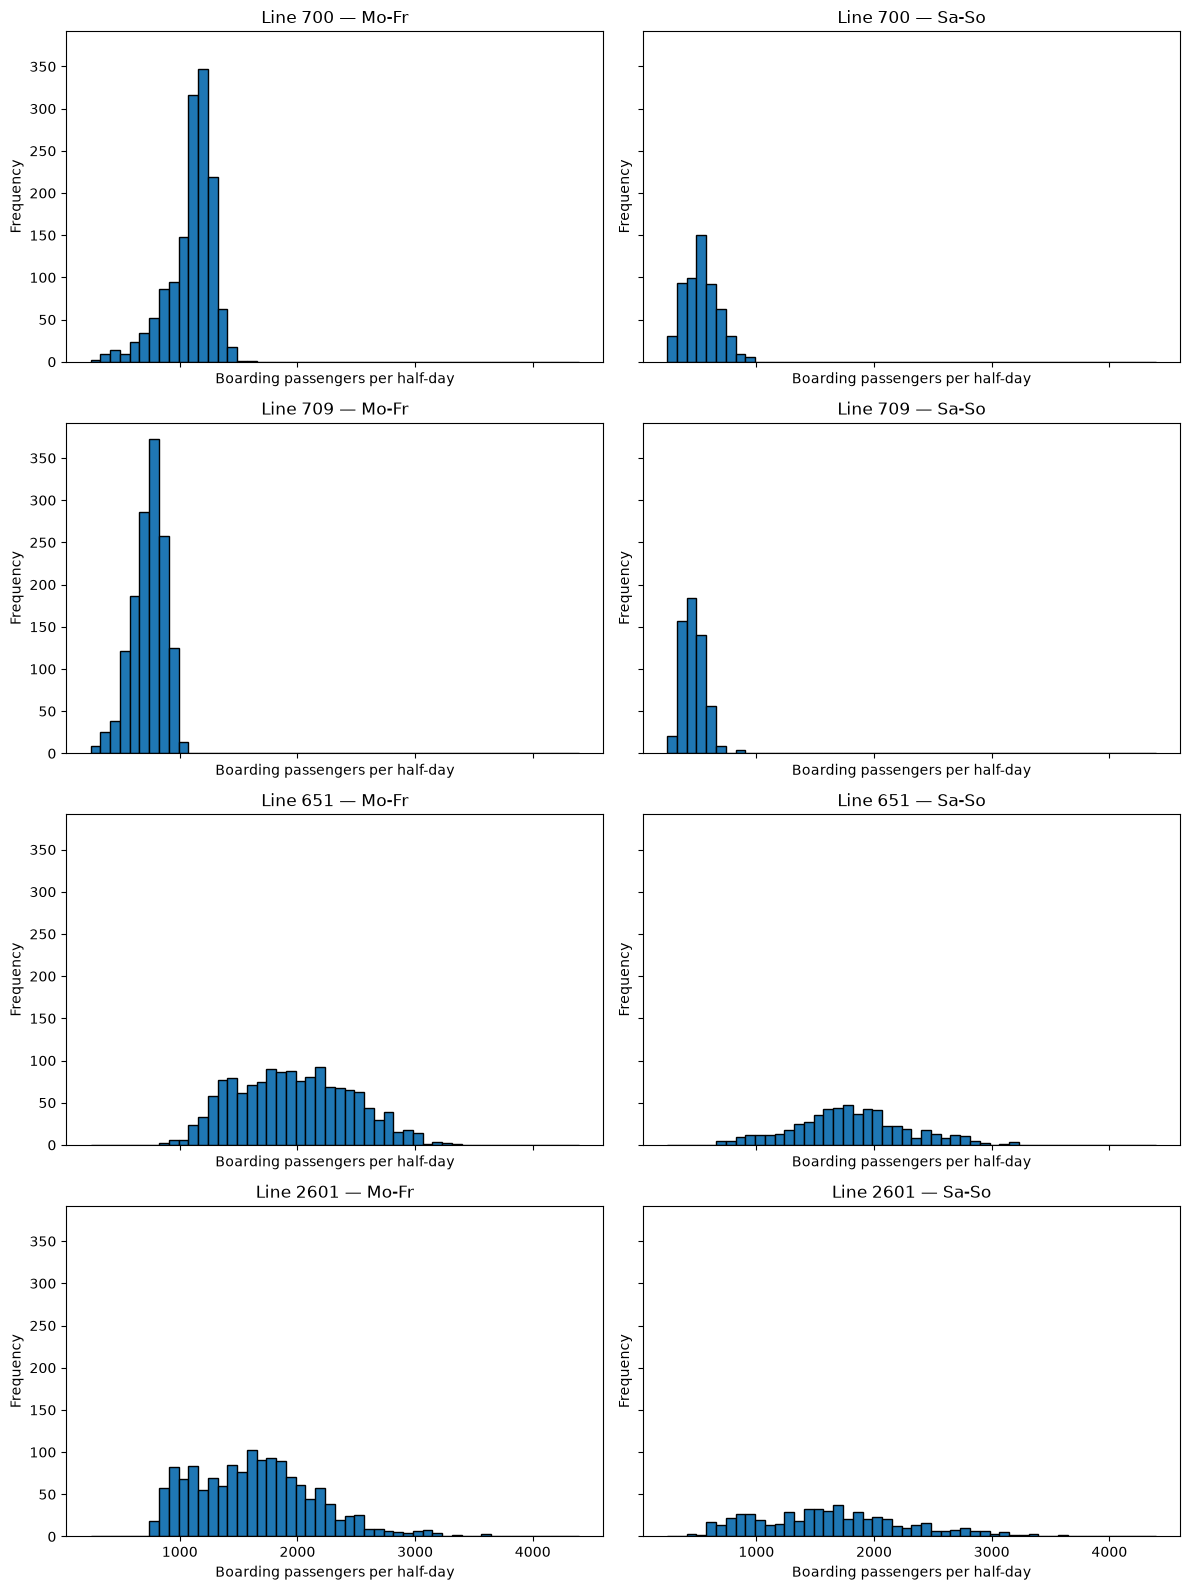

In [25]:
line_numbers = [700, 709, 651, 2601]
weekdaytypes = sorted(mean_passenger_frequencies_by_weekdaytype_timeofday["weekdaytype"].dropna().unique())

all_values = mean_passenger_frequencies_by_weekdaytype_timeofday.loc[
    mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"].isin(line_numbers),
    "boarding_mean",
].dropna()
bins = np.histogram_bin_edges(all_values, bins=50)

fig, axes = plt.subplots(
    len(line_numbers), len(weekdaytypes),
    figsize=(12, 4 * len(line_numbers)),
    sharex=True, sharey=True,
    squeeze=False,
)

for row, line_number in enumerate(line_numbers):
    for col, weekdaytype in enumerate(weekdaytypes):
        values = mean_passenger_frequencies_by_weekdaytype_timeofday.loc[
            (mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"] == line_number)
            & (mean_passenger_frequencies_by_weekdaytype_timeofday["weekdaytype"] == weekdaytype),
            "boarding_mean",
        ].dropna()

        ax = axes[row, col]
        ax.hist(values, bins=bins, edgecolor="black")
        ax.set_title(f"Line {line_number} — {weekdaytype}")
        ax.set_xlabel("Boarding passengers per half-day")
        ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 3. Statistical Analysis of the four Bus Lines

### 3.1 Touristic Lines

#### 3.1.1 Boxplots and Test for Normality

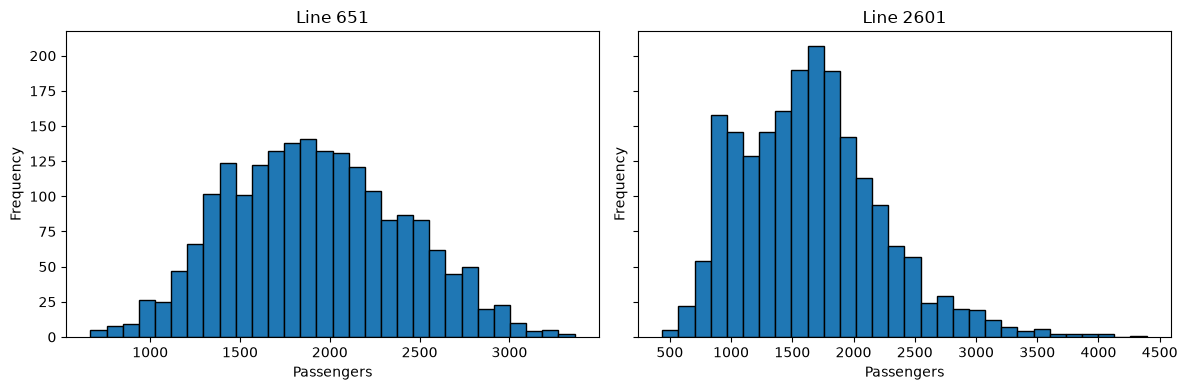

In [26]:
systemlinenumbers = [651, 2601]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, line_number in zip(axes, systemlinenumbers):
    values = mean_passenger_frequencies_by_weekdaytype_timeofday.loc[
        mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"] == line_number,
        "boarding_mean"
    ]
    ax.hist(values, bins=30, edgecolor="black")
    ax.set_title(f"Line {line_number}")
    ax.set_xlabel("Passengers")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

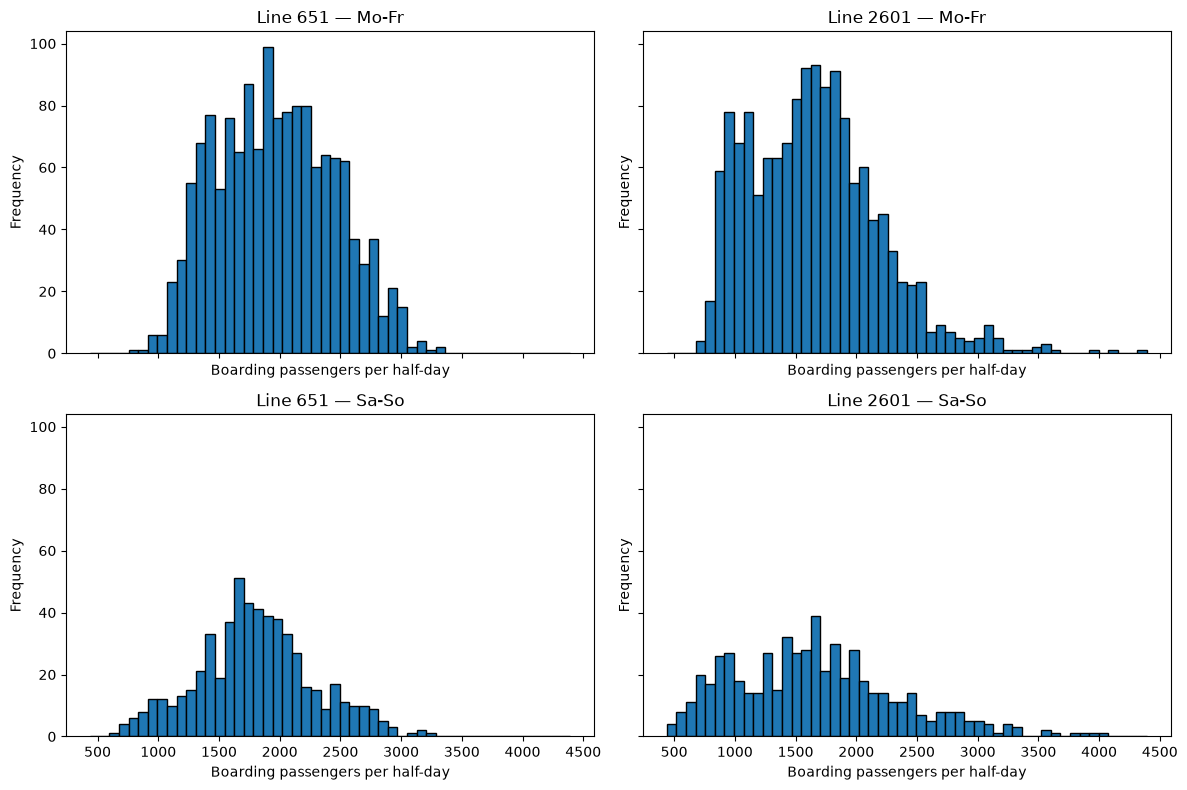

In [27]:
systemlinenumbers = [651, 2601]
weekdaytypes = sorted(mean_passenger_frequencies_by_weekdaytype_timeofday["weekdaytype"].dropna().unique())

selected = mean_passenger_frequencies_by_weekdaytype_timeofday[
    mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"].isin(systemlinenumbers)
]
all_values = selected["boarding_mean"].dropna()
bins = np.histogram_bin_edges(all_values, bins=50)

fig, axes = plt.subplots(
    len(systemlinenumbers), len(weekdaytypes),
    figsize=(12, 8),
    sharex=True, sharey=True,
    squeeze=False,
)

for col, line_number in enumerate(systemlinenumbers):
    for row, weekdaytype in enumerate(weekdaytypes):
        values = selected.loc[
            (selected["systemlinenumber"] == line_number)
            & (selected["weekdaytype"] == weekdaytype),
            "boarding_mean",
        ].dropna()

        ax = axes[row, col]
        ax.hist(values, bins=bins, edgecolor="black")
        ax.set_title(f"Line {line_number} — {weekdaytype}")
        ax.set_xlabel("Boarding passengers per half-day")
        ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [13]:
#function to create boxplots for the two lines 700 and 709
def boxplot_by_weekdaytype(systemlinenumbers, data):
    weekdaytypes = sorted(data["weekdaytype"].dropna().unique())

    fig, axes = plt.subplots(
        len(systemlinenumbers), len(weekdaytypes),
        figsize=(12, 4 * len(systemlinenumbers)),
        sharey=True,
        squeeze=False,
    )

    for col, line_number in enumerate(systemlinenumbers):
        for row, weekdaytype in enumerate(weekdaytypes):
            values = data.loc[
                (data["systemlinenumber"] == line_number)
                & (data["weekdaytype"] == weekdaytype),
                "boarding_mean",
            ].dropna()

            ax = axes[row, col]
            if len(values) == 0:
                ax.text(0.5, 0.5, "No data", ha="center", va="center")
                ax.set_axis_off()
                continue

            q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
            print(
                f"Line {line_number}, {weekdaytype}: "
                f"Q1={q1:.1f}, median={median:.1f}, Q3={q3:.1f}"
            )

            ax.boxplot(values)
            ax.set_title(f"Line {line_number}, {weekdaytype}")
            ax.set_xticks([1], [weekdaytype])
            ax.set_ylabel("Boarding mean")

    plt.tight_layout()
    plt.show()


Line 651, Mo-Fr: Q1=1587.8, median=1947.5, Q3=2324.0
Line 651, Sa-So: Q1=1501.8, median=1784.5, Q3=2073.5
Line 2601, Mo-Fr: Q1=1234.8, median=1620.5, Q3=1950.2
Line 2601, Sa-So: Q1=1131.5, median=1622.5, Q3=2052.0


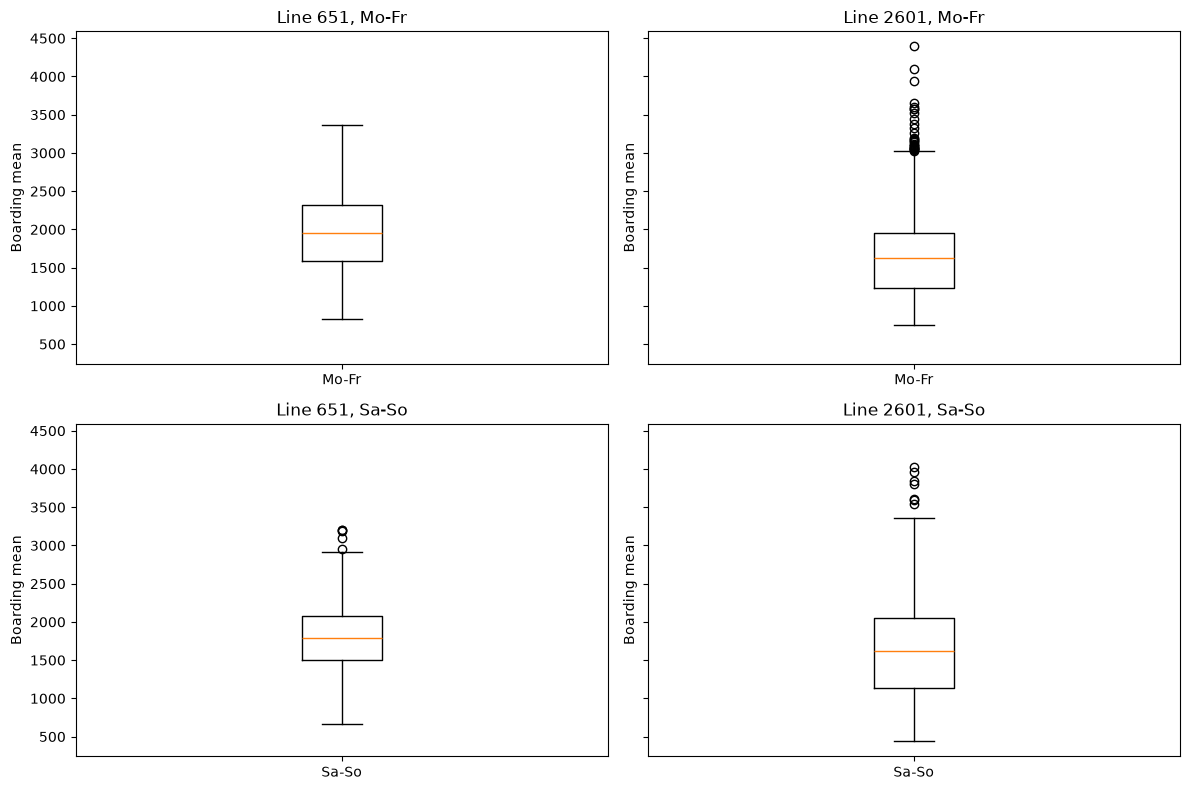

In [28]:
# make the boxplots for the two lines 651 and 2601
boxplot_by_weekdaytype(systemlinenumbers=[651, 2601], data=mean_passenger_frequencies_by_weekdaytype_timeofday)

In [31]:
# function to perform normality test and create Q-Q plots
def normality_test_qq(systemlinenumbers, data):
    weekdaytypes = sorted(data["weekdaytype"].dropna().unique())

    for line_number in systemlinenumbers:
        print(f"\n=== Line {line_number} ===")
        for weekdaytype in weekdaytypes:
            values = data.loc[
                (data["systemlinenumber"] == line_number)
                & (data["weekdaytype"] == weekdaytype),
                "boarding_mean",
            ].dropna()

            if len(values) < 3:
                print(f"  {weekdaytype}: insufficient data ({len(values)} observations)")
                continue

            stat, p = stats.shapiro(values)
            decision = "normal" if p > 0.05 else "not normal"
            print(f"  {weekdaytype}: statistic={stat:.4f}, p={p:.4g} -> {decision}")

    fig, axes = plt.subplots(
        len(systemlinenumbers),
        len(weekdaytypes),
        figsize=(14, 12),
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    for col, line_number in enumerate(systemlinenumbers):
        for row, weekdaytype in enumerate(weekdaytypes):
            values = data.loc[
                (data["systemlinenumber"] == line_number)
                & (data["weekdaytype"] == weekdaytype),
                "boarding_mean",
            ].dropna()

            ax = axes[row, col]
            if len(values) < 3:
                ax.text(0.5, 0.5, "Insufficient\ndata", ha="center", va="center")
                ax.set_axis_off()
                continue

            sm.qqplot(values, line="s", ax=ax)
            ax.set_title(f"Line {line_number}\n{weekdaytype}")

    plt.tight_layout()
    plt.show()



=== Line 651 ===
  Mo-Fr: statistic=0.9876, p=1.061e-09 -> not normal
  Sa-So: statistic=0.9926, p=0.006221 -> not normal

=== Line 2601 ===
  Mo-Fr: statistic=0.9596, p=1.592e-19 -> not normal
  Sa-So: statistic=0.9702, p=2.156e-09 -> not normal


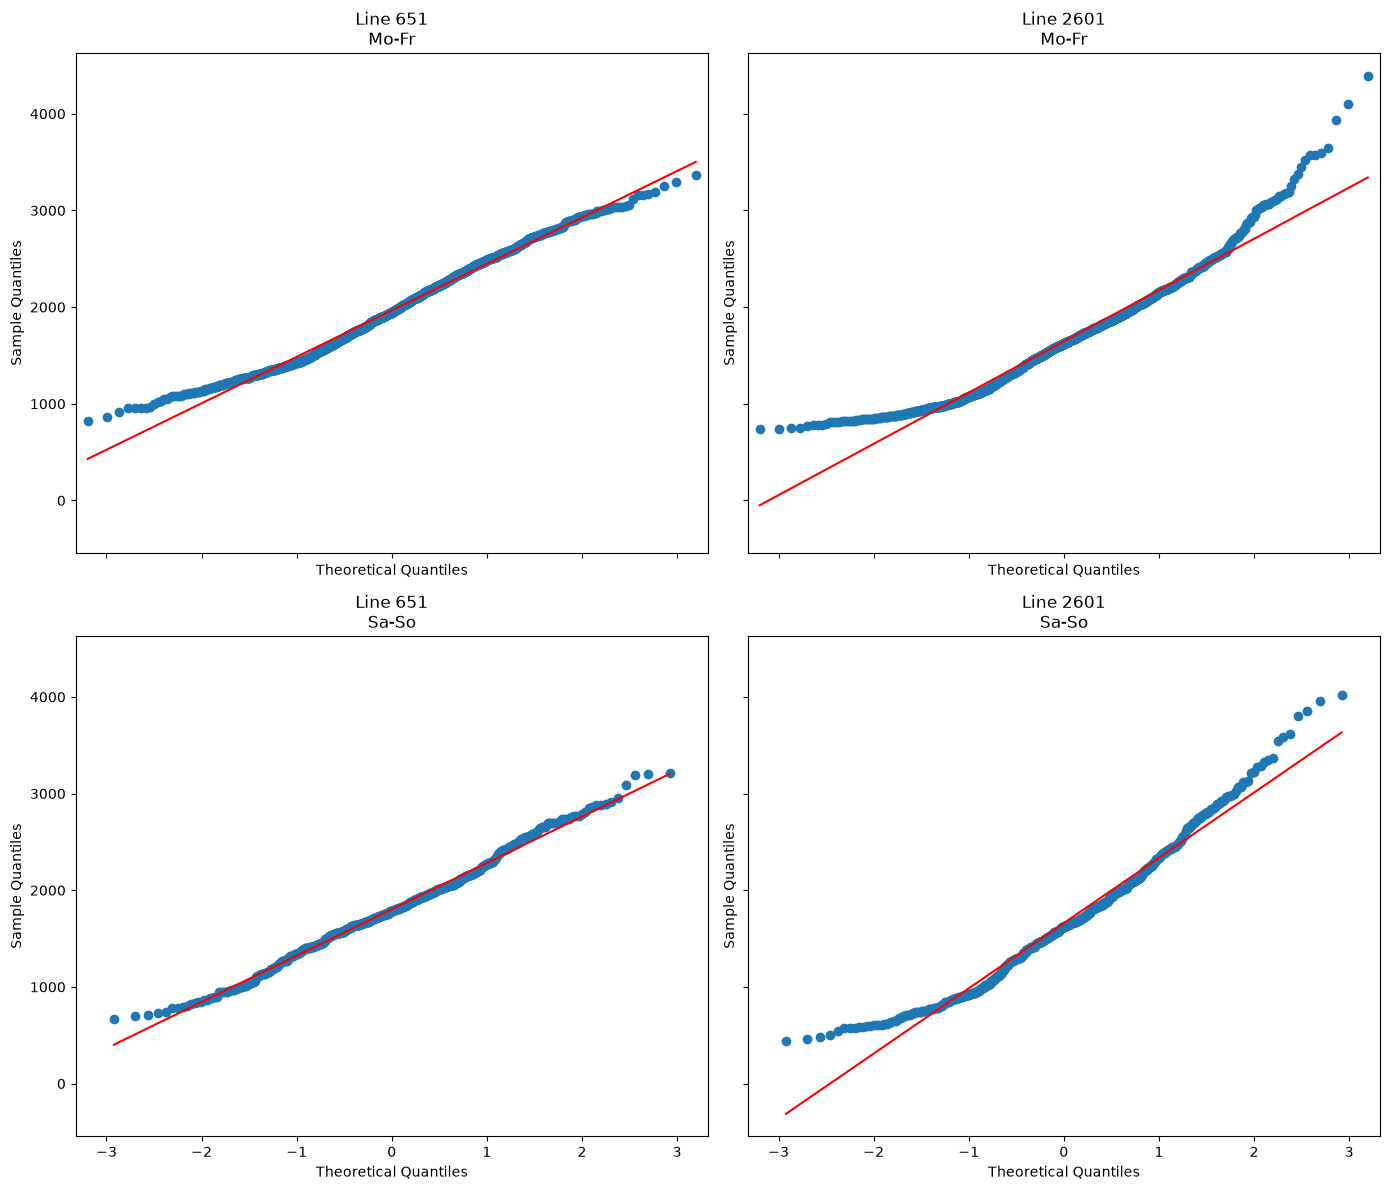

In [32]:
normality_test_qq(systemlinenumbers=[651, 2601], data=mean_passenger_frequencies_by_weekdaytype_timeofday)

#### 3.1.2 Mann-Whitney U Test

Within the tow lines, it is tested if the passenger frequency distribution is the same during the week and at the weekend.

Since the distributions are not normally distributed (non-parametric) and independent, the Mann-Whitney U test must be applied here.

In [39]:
# function to perform Mann-Whitney U test for two lines and two weekday types
def mann_whitney_by_weekdaytype(systemlinenumbers, data):
    results = {}

    for line_number in systemlinenumbers:
        mofr = data.loc[
            (data["systemlinenumber"] == line_number)
            & (data["weekdaytype"] == "Mo-Fr"),
            "boarding_mean",
        ].dropna()

        saso = data.loc[
            (data["systemlinenumber"] == line_number)
            & (data["weekdaytype"] == "Sa-So"),
            "boarding_mean",
        ].dropna()

        result = stats.mannwhitneyu(mofr, saso, alternative='two-sided')
        print(f"\nMann-Whitney U test: Line {line_number}, Mo-Fr vs Sa-So")
        print(result)
        results[line_number] = result

    return results


In [34]:
#perform Mann-Whitney U test for lines 651 and 2601
mwu_results = mann_whitney_by_weekdaytype(
    systemlinenumbers=[651, 2601],
    data=mean_passenger_frequencies_by_weekdaytype_timeofday,
)


Mann-Whitney U test: Line 651, Mo-Fr vs Sa-So
MannwhitneyuResult(statistic=np.float64(485518.5), pvalue=np.float64(1.765060322646905e-10))

Mann-Whitney U test: Line 2601, Mo-Fr vs Sa-So
MannwhitneyuResult(statistic=np.float64(415915.0), pvalue=np.float64(0.6563113631893729))


#### 3.1.3 Summary of the Statistical Analysis for the Touristic Lines

The normality checks indicate that the distributions of boarding counts are not normally distributed within the two selected touristic lines, neither for weekdays nor for weekends. This is confirmed by the Shapiro tests and the Q-Q plots, which show systematic deviations from a straight line. Because the assumptions for parametric tests are not met, the Mann-Whitney U test was used to compare the distributions of the two lines. The results show that for line 651, the weekday and weekend distributions are significantly different (p < 0.05), while for line 2601, no statistically significant difference was found between the two weekday types (p > 0.05). Overall, this suggests that the travel pattern of line 651 differs between weekdays and weekends, whereas line 2601 exhibits more similar behavior across these two periods.

### 3.2 Commuter Lines

#### 3.2.1 Boxplots and Test for Normality

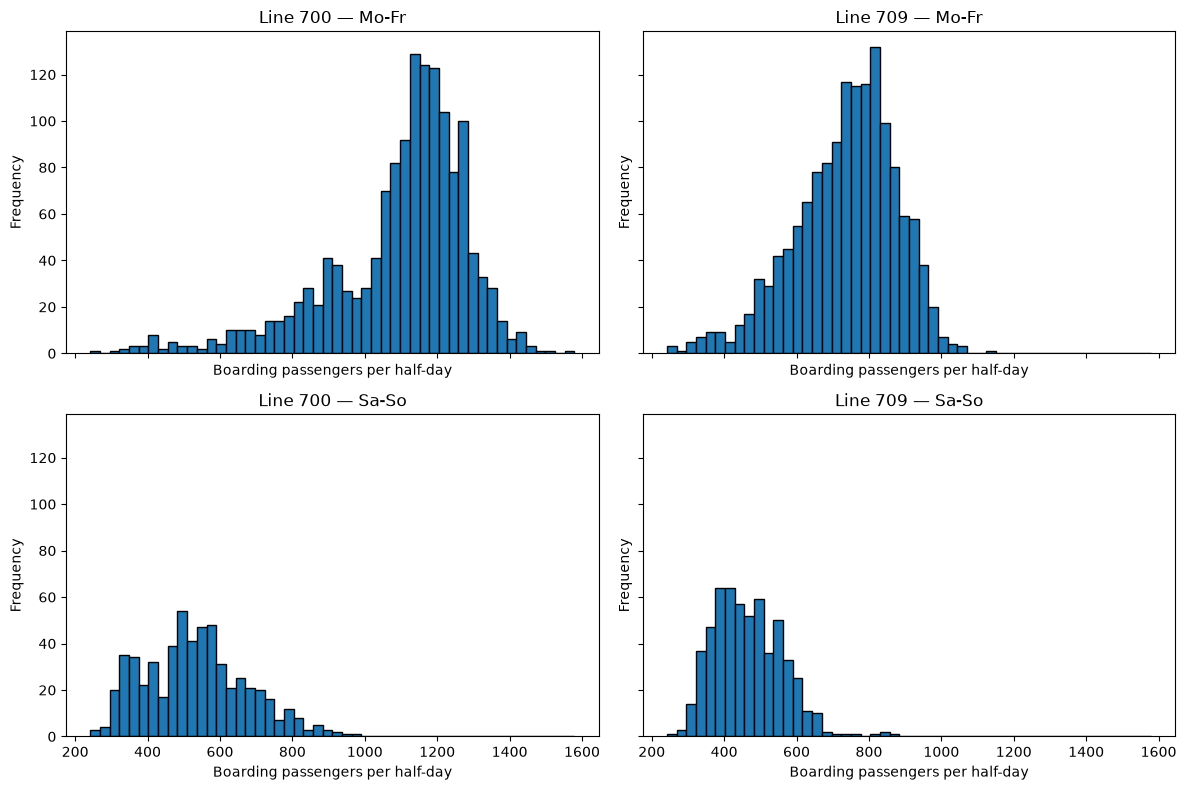

In [38]:
systemlinenumbers = [700, 709]
weekdaytypes = sorted(mean_passenger_frequencies_by_weekdaytype_timeofday["weekdaytype"].dropna().unique())

selected = mean_passenger_frequencies_by_weekdaytype_timeofday[
    mean_passenger_frequencies_by_weekdaytype_timeofday["systemlinenumber"].isin(systemlinenumbers)
]
all_values = selected["boarding_mean"].dropna()
bins = np.histogram_bin_edges(all_values, bins=50)

fig, axes = plt.subplots(
    len(systemlinenumbers), len(weekdaytypes),
    figsize=(12, 8),
    sharex=True, sharey=True,
    squeeze=False,
)

for col, line_number in enumerate(systemlinenumbers):
    for row, weekdaytype in enumerate(weekdaytypes):
        values = selected.loc[
            (selected["systemlinenumber"] == line_number)
            & (selected["weekdaytype"] == weekdaytype),
            "boarding_mean",
        ].dropna()

        ax = axes[row, col]
        ax.hist(values, bins=bins, edgecolor="black")
        ax.set_title(f"Line {line_number} — {weekdaytype}")
        ax.set_xlabel("Boarding passengers per half-day")
        ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Line 700, Mo-Fr: Q1=1020.0, median=1140.0, Q3=1221.0
Line 700, Sa-So: Q1=424.8, median=526.0, Q3=620.0
Line 709, Mo-Fr: Q1=652.0, median=754.0, Q3=833.0
Line 709, Sa-So: Q1=393.0, median=455.0, Q3=531.8


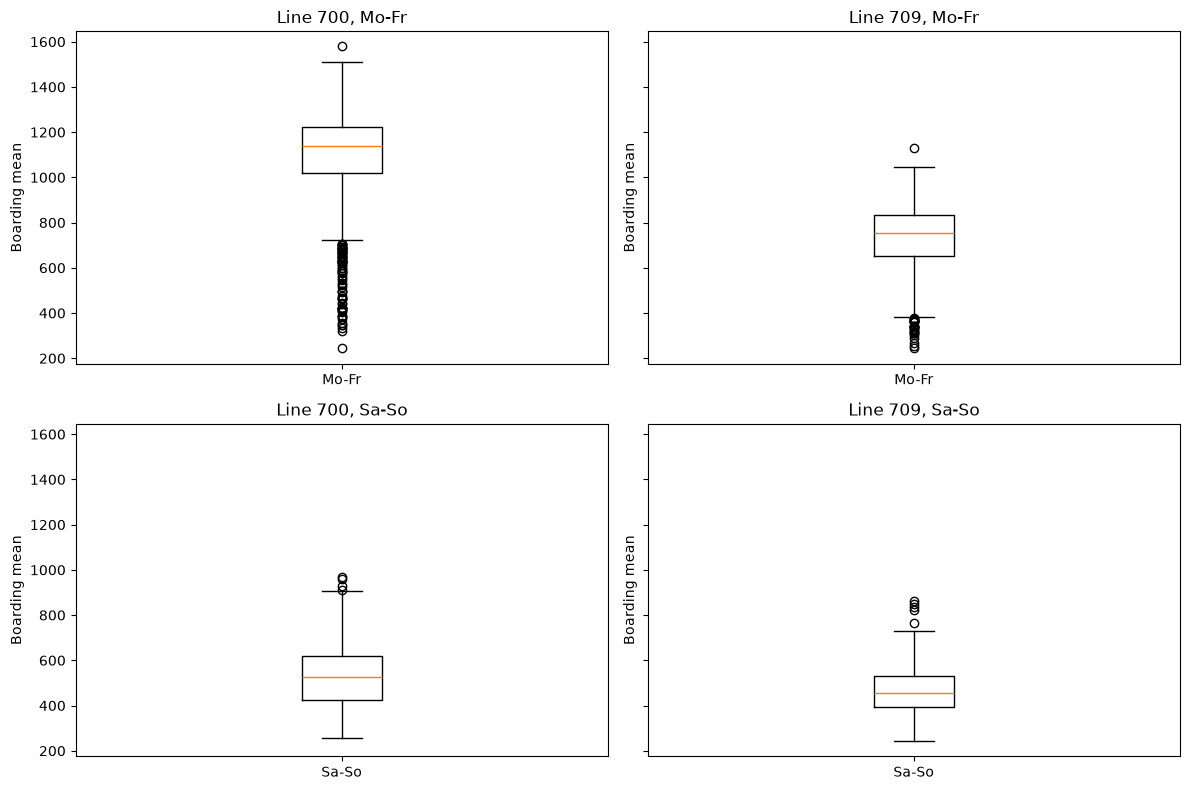

In [35]:
# make the boxplots for the two lines 700 and 709
boxplot_by_weekdaytype(systemlinenumbers=[700, 709], data=mean_passenger_frequencies_by_weekdaytype_timeofday)


=== Line 700 ===
  Mo-Fr: statistic=0.9070, p=1.018e-28 -> not normal
  Sa-So: statistic=0.9802, p=5.214e-07 -> not normal

=== Line 709 ===
  Mo-Fr: statistic=0.9786, p=8.556e-14 -> not normal
  Sa-So: statistic=0.9719, p=5.155e-09 -> not normal


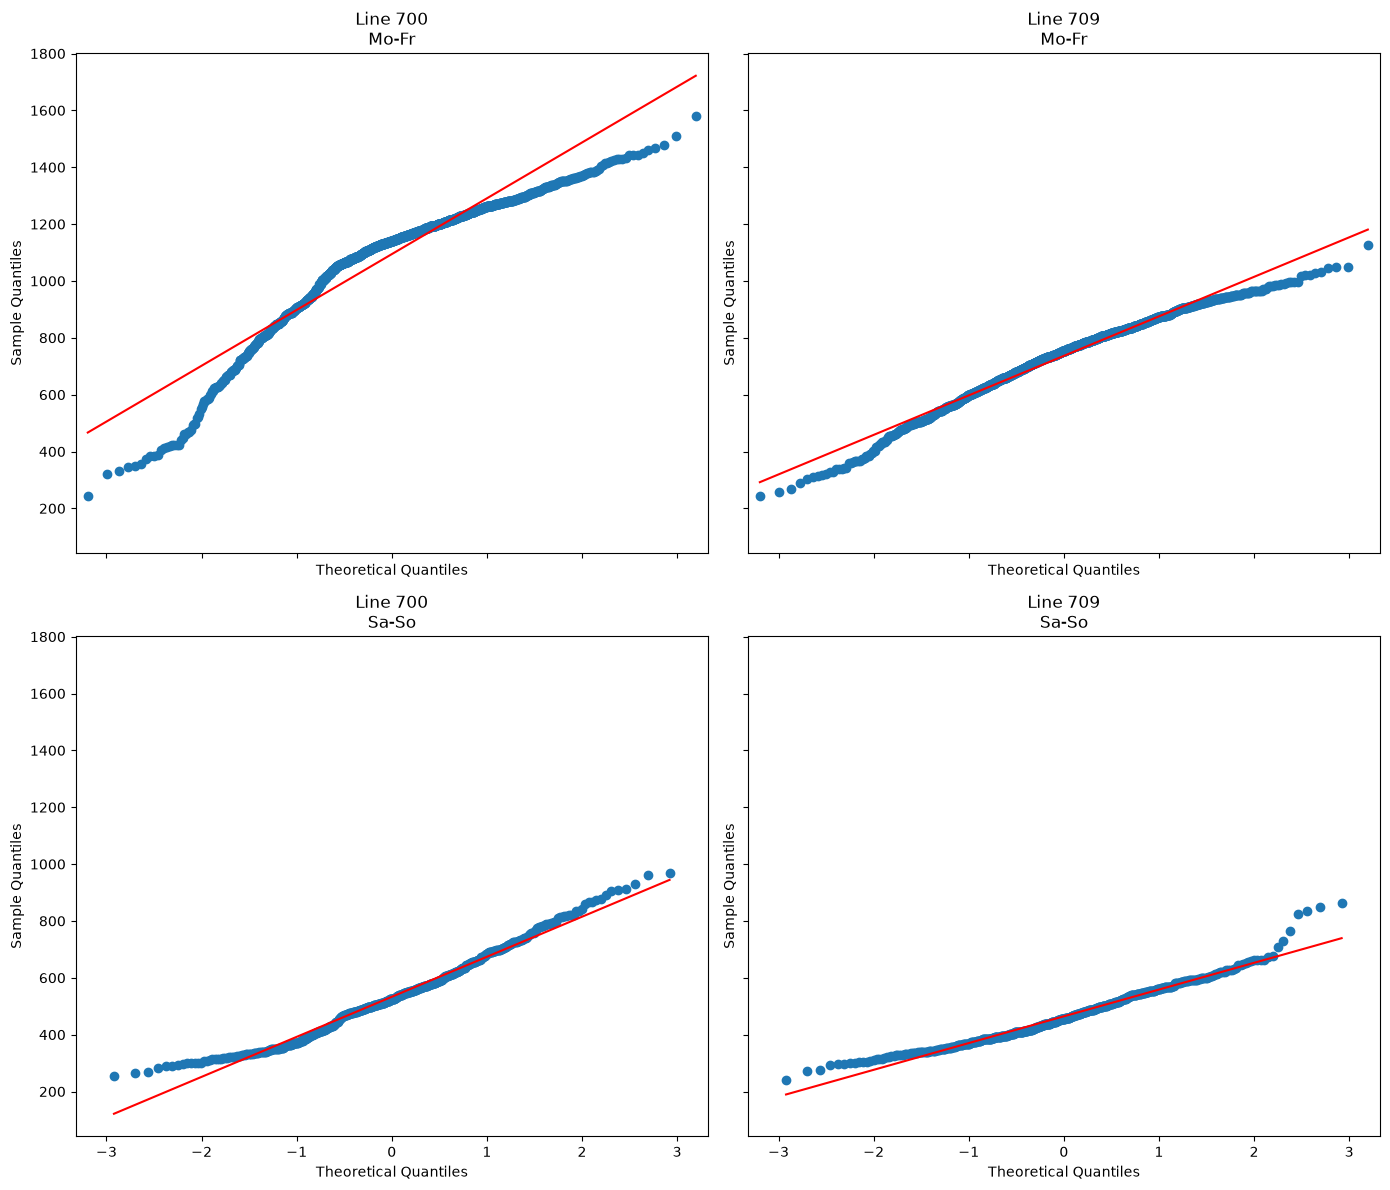

In [36]:
# perform normality test and create Q-Q plots for lines 700 and 709
normality_test_qq(systemlinenumbers=[700, 709], data=mean_passenger_frequencies_by_weekdaytype_timeofday)

#### 3.2.2 Mann-Whitney U Test

Within the tow  commuter lines, it is tested if the passenger frequency distribution is the same during the week and at the weekend.

In [37]:
# perform Mann-Whitney U test for lines 700 and 709
mwu_results = mann_whitney_by_weekdaytype(
    systemlinenumbers=[700, 709],
    data=mean_passenger_frequencies_by_weekdaytype_timeofday,
)


Mann-Whitney U test: Line 700, Mo-Fr vs Sa-So
MannwhitneyuResult(statistic=np.float64(798998.0), pvalue=np.float64(1.9475584563113876e-240))

Mann-Whitney U test: Line 709, Mo-Fr vs Sa-So
MannwhitneyuResult(statistic=np.float64(767997.5), pvalue=np.float64(6.674651767088787e-204))


#### 3.2.3 Summary of the Statistical Analysis for the Commuter Lines

The Shapiro-Wilk tests reject normality for both weekday types on lines 700 and 709 (all p-values < 0.001), which is also reflected in departures from the reference lines in the Q-Q plots.

Therefore, the non-parametric Mann-Whitney U test was used to compare weekdays (Mo-Fr) with weekends (Sa-So) within each line. The differences are statistically significant for line 700 (U = 690,863, p = 3.76e-126) and line 709 (U = 745,414, p = 3.40e-179). The boxplots show higher weekday medians than weekend medians for both lines (line 700: 36.4 vs 26.7; line 709: 36.9 vs 24.7).

Together, these results indicate that passenger-frequency distributions differ between weekdays and weekends on both commuter lines, with higher central values on weekdays.

## 4. Conclusion

Passenger-frequency distributions were not normally distributed, so weekday and weekend patterns were compared using Mann-Whitney U tests.

The distributions differed significantly between Mo-Fr and Sa-So on lines 651, 700, and 709; line 2601 showed no significant difference.

Weekday medians were higher on all four lines, although the difference for commuter lines was much larger than for touristic lines (where one showed no statistically significant difference at the 5% level).